In [2]:
import os

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import sys
import json
import time
from collections import Counter

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

print("Verwendetes Python :", sys.executable)
print("Torch-Version :", torch.__version__)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Gerät :", DEVICE)


Verwendetes Python : C:\Users\Lenovo\anaconda3\python.exe
Torch-Version : 2.12.0+cpu
Gerät : cpu


## 1bis. Konfiguration von Weights & Biases

In [3]:
import sys
!{sys.executable} -m pip install wandb -q
import wandb

WANDB_ENTITY = "eidl-thm"
WANDB_PROJECT = "Uebungabgabe3_Vades_Ngounouo__Lister_Melaguie"
WANDB_REQUIRED = True

# Force online sync so runs are visible to the team dashboard.
wandb.require("core")
WANDB_AVAILABLE = False
try:
    wandb.login(relogin=True)
    api = wandb.Api()
    _ = api.project(f"{WANDB_ENTITY}/{WANDB_PROJECT}")
    WANDB_AVAILABLE = True
    print(f"W&B OK: Zugriff auf {WANDB_ENTITY}/{WANDB_PROJECT}")
except Exception as e:
    WANDB_AVAILABLE = False
    print(f"W&B nicht bereit: {e}")
    if WANDB_REQUIRED:
        raise RuntimeError(
            f"W&B ist erforderlich, aber Login/Zugriff auf {WANDB_ENTITY}/{WANDB_PROJECT} fehlt. "
            "Bitte mit einem Team-Account einloggen, der Projektzugriff hat."
        ) from e

wandb: WARNING `wandb.require('core')` is a no-op as it is now the default behavior.
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice:

  2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.
wandb: Paste your API key and hit enter:

  ········


wandb: Appending key for api.wandb.ai to your netrc file: C:\Users\Lenovo\_netrc
wandb: Currently logged in as: vadesdjoko (eidl-thm) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


W&B OK: Zugriff auf eidl-thm/Uebungabgabe3_Vades_Ngounouo__Lister_Melaguie


## 2. Laden von train.json / validation.json

In [6]:
PATH_TRAIN_JSON = "./train.json"
PATH_VAL_JSON = "./validation.json"

with open(PATH_TRAIN_JSON, "r", encoding="utf-8") as f:
    train_raw = json.load(f)

with open(PATH_VAL_JSON, "r", encoding="utf-8") as f:
    val_raw = json.load(f)

print("Typ von train_raw :", type(train_raw))
print("Anzahl der Elemente (Training) :", len(train_raw))

# Anzeige des ersten Elements, um seine genaue Struktur zu sehen
print("\nErstes Element :")
print(train_raw[0])


Typ von train_raw : <class 'list'>
Anzahl der Elemente (Training) : 214122

Erstes Element :
{'control code': 'S:2\nB:5\nE:5\nB:6\n', 'abc notation': 'X:1\nL:1/8\nM:4/4\nK:Emin\n|: E2 EF E2 EF | DEFG AFDF | E2 EF E2 B2 |1 efe^d e2 e2 :|2 efe^d e3 B |: e2 ef g2 fe | \n defg afdf |1 e2 ef g2 fe | efe^d e3 B :|2 g2 bg f2 af | efe^d e2 e2 ||'}


In [7]:
def extract_abc_field(entry):
    """
    Extrahiert das Feld mit der ABC-Notation aus einem Element des Datensatzes,
    unabhängig von Groß-/Kleinschreibung oder genauem Schlüsselnamen (z.B. 'abc notation', 'abc', 'ABC').
    Ist das Element bereits eine Zeichenkette, wird sie unverändert zurückgegeben.
    """
    if isinstance(entry, str):
        return entry

    if isinstance(entry, dict):
        for key in entry.keys():
            if "abc" in key.lower():
                return entry[key]
        raise KeyError(f"Kein Schlüssel mit 'abc' gefunden unter : {list(entry.keys())}")

    raise TypeError(f"Unerwarteter Elementtyp : {type(entry)}")


# Test am ersten Element
sample_abc = extract_abc_field(train_raw[0])
print("Erkannter ABC-Ausschnitt :\n", sample_abc[:300])


Erkannter ABC-Ausschnitt :
 X:1
L:1/8
M:4/4
K:Emin
|: E2 EF E2 EF | DEFG AFDF | E2 EF E2 B2 |1 efe^d e2 e2 :|2 efe^d e3 B |: e2 ef g2 fe | 
 defg afdf |1 e2 ef g2 fe | efe^d e3 B :|2 g2 bg f2 af | efe^d e2 e2 ||


In [8]:
train_tunes = [extract_abc_field(entry) for entry in train_raw]
val_tunes = [extract_abc_field(entry) for entry in val_raw]

print(f"Trainingsstücke : {len(train_tunes)}")
print(f"Validierungsstücke : {len(val_tunes)}")


Trainingsstücke : 214122
Validierungsstücke : 2162


## 3. Aufbau des Vokabulars (zeichenweise Tokenisierung)

In [9]:
def build_vocab(tunes):
    """Baut ein zeichenweises Vokabular aus allen Musikstücken auf."""
    all_text = "".join(tunes)
    chars = sorted(set(all_text))

    char2idx = {ch: i for i, ch in enumerate(chars)}
    idx2char = {i: ch for i, ch in enumerate(chars)}

    return char2idx, idx2char

char2idx, idx2char = build_vocab(train_tunes)
VOCAB_SIZE = len(char2idx)
print(f"Vokabulargröße : {VOCAB_SIZE}")

def encode(text, char2idx):
    """Wandelt eine Zeichenkette in eine Liste von Indizes um (ignoriert unbekannte Zeichen)."""
    return [char2idx[ch] for ch in text if ch in char2idx]


Vokabulargröße : 95


## 4. PyTorch-Dataset

In [10]:
class ABCDataset(Dataset):
    def __init__(self, tunes, char2idx, seq_length=100, stride=25):
        self.seq_length = seq_length
        self.char2idx = char2idx

        # Jedes Stück wird nur einmal kodiert (keine Duplizierung pro Fenster)
        self.encoded_tunes = [encode(tune, char2idx) for tune in tunes]

        # stride > 1 : es wird nicht bei JEDEM Zeichen ein neues Fenster erzeugt,
        # sondern nur alle `stride` Zeichen. Das reduziert die Anzahl der Beispiele
        # (und damit die Batches pro Epoche) drastisch, ohne viel Lernsignal zu verlieren,
        # da aufeinanderfolgende Fenster ohnehin fast identisch sind.
        self.index = []
        for tune_idx, encoded in enumerate(self.encoded_tunes):
            n_positions = len(encoded) - seq_length
            if n_positions > 0:
                for i in range(0, n_positions, stride):
                    self.index.append((tune_idx, i))

    def __len__(self):
        return len(self.index)

    def __getitem__(self, idx):
        tune_idx, i = self.index[idx]
        encoded = self.encoded_tunes[tune_idx]
        seq_length = self.seq_length

        input_seq = encoded[i:i + seq_length]
        target_seq = encoded[i + 1:i + seq_length + 1]

        return torch.tensor(input_seq, dtype=torch.long), torch.tensor(target_seq, dtype=torch.long)


In [11]:
SEQ_LENGTH = 100
STRIDE = 1000

train_dataset = ABCDataset(train_tunes, char2idx, seq_length=SEQ_LENGTH, stride=STRIDE)
val_dataset = ABCDataset(val_tunes, char2idx, seq_length=SEQ_LENGTH, stride=STRIDE)

print(f"Anzahl der Trainingsbeispiele : {len(train_dataset)}")
print(f"Anzahl der Validierungsbeispiele : {len(val_dataset)}")

BATCH_SIZE = 64
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

x_batch, y_batch = next(iter(train_loader))
print("Form input :", x_batch.shape)
print("Form target :", y_batch.shape)


Anzahl der Trainingsbeispiele : 213076
Anzahl der Validierungsbeispiele : 2142
Form input : torch.Size([64, 100])
Form target : torch.Size([64, 100])


## 5. RNN-/LSTM-Modell

In [12]:
class MusicRNN(nn.Module):
    """
    Modell zur Erzeugung von Sequenzen (ABC-Zeichen) basierend auf RNN oder LSTM.
    Nimmt eine Token-Sequenz als Eingabe und sagt das nächste Token voraus.
    """
    def __init__(self, vocab_size, embedding_dim=256, hidden_dim=512,
                 num_layers=2, rnn_type="lstm", dropout=0.3):
        super(MusicRNN, self).__init__()

        self.vocab_size = vocab_size
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers
        self.rnn_type = rnn_type.lower()

        self.embedding = nn.Embedding(vocab_size, embedding_dim)

        if self.rnn_type == "lstm":
            self.rnn = nn.LSTM(
                input_size=embedding_dim,
                hidden_size=hidden_dim,
                num_layers=num_layers,
                batch_first=True,
                dropout=dropout if num_layers > 1 else 0.0
            )
        elif self.rnn_type == "rnn":
            self.rnn = nn.RNN(
                input_size=embedding_dim,
                hidden_size=hidden_dim,
                num_layers=num_layers,
                batch_first=True,
                nonlinearity="tanh",
                dropout=dropout if num_layers > 1 else 0.0
            )
        else:
            raise ValueError("rnn_type muss 'rnn' oder 'lstm' sein")

        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x, hidden=None):
        batch_size = x.size(0)

        if hidden is None:
            hidden = self.init_hidden(batch_size, x.device)

        embedded = self.embedding(x)
        out, hidden = self.rnn(embedded, hidden)
        out = self.dropout(out)
        logits = self.fc(out)

        return logits, hidden

    def init_hidden(self, batch_size, device):
        if self.rnn_type == "lstm":
            h0 = torch.zeros(self.num_layers, batch_size, self.hidden_dim, device=device)
            c0 = torch.zeros(self.num_layers, batch_size, self.hidden_dim, device=device)
            return (h0, c0)
        else:
            h0 = torch.zeros(self.num_layers, batch_size, self.hidden_dim, device=device)
            return h0


In [13]:
model = MusicRNN(
    vocab_size=VOCAB_SIZE,
    embedding_dim=128,
    hidden_dim=256,
    num_layers=1,
    rnn_type="lstm"
).to(DEVICE)

print(model)

batch_size_test, seq_len_test = 4, 50
dummy_input = torch.randint(0, VOCAB_SIZE, (batch_size_test, seq_len_test)).to(DEVICE)
logits, hidden = model(dummy_input)
print("Form der Logits :", logits.shape)


MusicRNN(
  (embedding): Embedding(95, 128)
  (rnn): LSTM(128, 256, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=95, bias=True)
)
Form der Logits : torch.Size([4, 50, 95])


## 6. Training

In [14]:
def train_one_epoch(model, dataloader, optimizer, criterion, device, clip_grad=5.0,
                     log_every=50, log_file=None, use_wandb=False, epoch=None):
    model.train()
    total_loss = 0.0
    n_batches = len(dataloader)

    for batch_idx, (inputs, targets) in enumerate(dataloader):
        try:
            inputs, targets = inputs.to(device), targets.to(device)

            optimizer.zero_grad()
            logits, _ = model(inputs)
            loss = criterion(logits.view(-1, logits.size(-1)), targets.view(-1))
            loss.backward()

            torch.nn.utils.clip_grad_norm_(model.parameters(), clip_grad)
            optimizer.step()

            total_loss += loss.item()

        except torch.cuda.OutOfMemoryError as e:
            msg = f"[OOM] Batch {batch_idx}/{n_batches} - {e}"
            print(msg)
            if log_file:
                with open(log_file, "a") as f:
                    f.write(msg + "\n")
            torch.cuda.empty_cache()
            raise

        if batch_idx % log_every == 0:
            mem_str = ""
            gpu_mem_alloc = gpu_mem_reserved = None
            if device.type == "cuda":
                gpu_mem_alloc = torch.cuda.memory_allocated(device) / 1024**2
                gpu_mem_reserved = torch.cuda.memory_reserved(device) / 1024**2
                mem_str = f" | GPU-Speicher alloc={gpu_mem_alloc:.0f}MB reserved={gpu_mem_reserved:.0f}MB"

            msg = f"  Batch {batch_idx}/{n_batches} | loss={loss.item():.4f}{mem_str}"
            print(msg, flush=True)
            if log_file:
                with open(log_file, "a") as f:
                    f.write(msg + "\n")

            if use_wandb:
                log_dict = {
                    "batch_loss": loss.item(),
                    "batch": batch_idx,
                }
                if epoch is not None:
                    log_dict["epoch"] = epoch
                if gpu_mem_alloc is not None:
                    log_dict["gpu_mem_alloc_MB"] = gpu_mem_alloc
                    log_dict["gpu_mem_reserved_MB"] = gpu_mem_reserved
                wandb.log(log_dict)

    return total_loss / len(dataloader)


@torch.no_grad()
def evaluate(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0.0

    for inputs, targets in dataloader:
        inputs, targets = inputs.to(device), targets.to(device)
        logits, _ = model(inputs)
        loss = criterion(logits.view(-1, logits.size(-1)), targets.view(-1))
        total_loss += loss.item()

    return total_loss / len(dataloader)


In [15]:
def train_model(model, train_loader, val_loader, device,
                 num_epochs=20, learning_rate=1e-3, weight_decay=0.0,
                 patience=3, save_path="best_model.pt", log_file="training_log.txt",
                 use_wandb=False, wandb_project="abc-music-rnn", wandb_run_name=None,
                 wandb_config=None, wandb_entity=None):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=1)

    history = {"train_loss": [], "val_loss": []}
    best_val_loss = float("inf")
    epochs_no_improve = 0

    if log_file:
        with open(log_file, "w") as f:
            f.write(f"Trainingsbeginn - Gerät={device}\n")

    wandb_enabled = bool(use_wandb)
    if wandb_enabled:
        config = dict(wandb_config) if wandb_config else {}
        config.update({
            "num_epochs": num_epochs,
            "learning_rate": learning_rate,
            "weight_decay": weight_decay,
            "batch_size": train_loader.batch_size,
            "device": str(device),
        })
        try:
            wandb.init(
                project=wandb_project,
                entity=wandb_entity,
                name=wandb_run_name,
                config=config,
                reinit=True,
            )
            wandb.watch(model, log="all", log_freq=100)
            print("W&B aktiviert.")
        except Exception as e:
            warn_msg = f"W&B deaktiviert (Init-Fehler): {e}"
            print(warn_msg)
            if log_file:
                with open(log_file, "a") as f:
                    f.write(warn_msg + "\n")
            wandb_enabled = False

    for epoch in range(1, num_epochs + 1):
        start = time.time()

        msg = f"--- Epoche {epoch}/{num_epochs} ---"
        print(msg)
        if log_file:
            with open(log_file, "a") as f:
                f.write(msg + "\n")

        train_loss = train_one_epoch(model, train_loader, optimizer, criterion, device,
                                      log_file=log_file, use_wandb=wandb_enabled, epoch=epoch)
        val_loss = evaluate(model, val_loader, criterion, device)

        scheduler.step(val_loss)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        elapsed = time.time() - start
        current_lr = optimizer.param_groups[0]['lr']
        msg = (f"Epoche {epoch}/{num_epochs} | "
               f"Trainingsverlust : {train_loss:.4f} | Validierungsverlust : {val_loss:.4f} | "
               f"LR : {current_lr:.6f} | Zeit : {elapsed:.1f}s")
        print(msg)
        if log_file:
            with open(log_file, "a") as f:
                f.write(msg + "\n")

        if wandb_enabled:
            wandb.log({
                "epoch": epoch,
                "train_loss": train_loss,
                "val_loss": val_loss,
                "learning_rate": current_lr,
                "epoch_time_s": elapsed,
            })

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            epochs_no_improve = 0
            torch.save(model.state_dict(), save_path)
            if wandb_enabled:
                wandb.save(save_path)
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                msg = f"Early Stopping bei Epoche {epoch} (keine Verbesserung seit {patience} Epochen)"
                print(msg)
                if log_file:
                    with open(log_file, "a") as f:
                        f.write(msg + "\n")
                break

    if wandb_enabled:
        wandb.unwatch(model) 
        wandb.finish()

    return history


In [16]:
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
NUM_EPOCHS = 5

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

model = MusicRNN(vocab_size=VOCAB_SIZE, embedding_dim=256, hidden_dim=512,
                  num_layers=2, rnn_type="lstm").to(DEVICE)

history = train_model(
    model, train_loader, val_loader, DEVICE,
    num_epochs=NUM_EPOCHS, learning_rate=LEARNING_RATE,
    use_wandb=WANDB_AVAILABLE,
    wandb_entity=WANDB_ENTITY,
    wandb_project=WANDB_PROJECT,
    wandb_config={
        "embedding_dim": 256,
        "hidden_dim": 512,
        "num_layers": 2,
        "rnn_type": "lstm",
        "seq_length": SEQ_LENGTH,
        "vocab_size": VOCAB_SIZE,
    },
)


wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


W&B aktiviert.
--- Epoche 1/5 ---
  Batch 0/1665 | loss=4.5483
  Batch 50/1665 | loss=1.9735
  Batch 100/1665 | loss=1.5747
  Batch 150/1665 | loss=1.4050
  Batch 200/1665 | loss=1.3273
  Batch 250/1665 | loss=1.2159
  Batch 300/1665 | loss=1.2009
  Batch 350/1665 | loss=1.1694
  Batch 400/1665 | loss=1.1298
  Batch 450/1665 | loss=1.0843
  Batch 500/1665 | loss=1.0974
  Batch 550/1665 | loss=1.1063
  Batch 600/1665 | loss=1.1085
  Batch 650/1665 | loss=1.0251
  Batch 700/1665 | loss=1.0189
  Batch 750/1665 | loss=1.0554
  Batch 800/1665 | loss=1.0622
  Batch 850/1665 | loss=1.0373
  Batch 900/1665 | loss=1.0493
  Batch 950/1665 | loss=0.9938
  Batch 1000/1665 | loss=1.0617
  Batch 1050/1665 | loss=0.9917
  Batch 1100/1665 | loss=1.0152
  Batch 1150/1665 | loss=1.0015
  Batch 1200/1665 | loss=1.0248
  Batch 1250/1665 | loss=0.9695
  Batch 1300/1665 | loss=0.9936
  Batch 1350/1665 | loss=1.0334
  Batch 1400/1665 | loss=1.0071
  Batch 1450/1665 | loss=0.9687
  Batch 1500/1665 | loss=1.00

wandb: WARNING Linked 1 file into the W&B run directory (hardlinks); call wandb.save again to sync new files.


--- Epoche 2/5 ---
  Batch 0/1665 | loss=0.9739
  Batch 50/1665 | loss=0.9821
  Batch 100/1665 | loss=0.9634
  Batch 150/1665 | loss=0.9678
  Batch 200/1665 | loss=0.9415
  Batch 250/1665 | loss=0.9636
  Batch 300/1665 | loss=0.9248
  Batch 350/1665 | loss=0.9452
  Batch 400/1665 | loss=0.9588
  Batch 450/1665 | loss=0.9343
  Batch 500/1665 | loss=0.9440
  Batch 550/1665 | loss=0.9158
  Batch 600/1665 | loss=0.9619
  Batch 650/1665 | loss=0.9300
  Batch 700/1665 | loss=0.9246
  Batch 750/1665 | loss=0.9391
  Batch 800/1665 | loss=0.9366
  Batch 850/1665 | loss=0.9105
  Batch 900/1665 | loss=0.9431
  Batch 950/1665 | loss=0.9243
  Batch 1000/1665 | loss=0.9216
  Batch 1050/1665 | loss=0.9308
  Batch 1100/1665 | loss=0.9233
  Batch 1150/1665 | loss=0.9138
  Batch 1200/1665 | loss=0.9090
  Batch 1250/1665 | loss=0.9317
  Batch 1300/1665 | loss=0.9575
  Batch 1350/1665 | loss=0.9120
  Batch 1400/1665 | loss=0.9308
  Batch 1450/1665 | loss=0.9117
  Batch 1500/1665 | loss=0.8825
  Batch 1550

batch,▁▂▅▅▅▆▆▇▇▁▂▄▆▆▇▂▂▃▄▄▅▆▇▇█▃▃▃▄▅██▁▂▃▄▅▇▇█
batch_loss,█▃▃▃▂▂▂▂▂▂▂▂▂▁▂▂▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
epoch,▁▁▁▁▁▁▁▃▃▃▃▃▅▅▅▅▅▅▅▅▅▆▆▆▆▆▆▆▆▆▆█████████
epoch_time_s,▅▁▂█▇
learning_rate,▁▁▁▁▁
train_loss,█▃▂▁▁
val_loss,█▅▃▂▁
batch,1650
batch_loss,0.87151
epoch,5
epoch_time_s,2549.87005


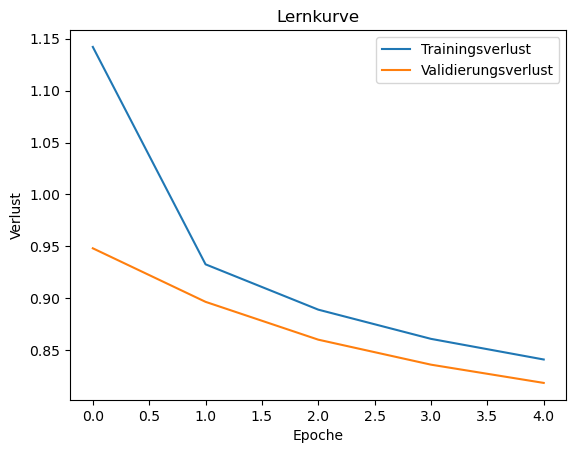

In [17]:
plt.plot(history["train_loss"], label="Trainingsverlust")
plt.plot(history["val_loss"], label="Validierungsverlust")
plt.xlabel("Epoche")
plt.ylabel("Verlust")
plt.legend()
plt.title("Lernkurve")
plt.show()


## 7. Music Generation

In [18]:
@torch.no_grad()
def sample_next_token(logits, temperature=1.0, top_k=None):
    """Sample one token index from logits using temperature and optional top-k filtering."""
    if temperature <= 0:
        raise ValueError("temperature muss > 0 sein")

    logits = logits / temperature

    if top_k is not None and top_k > 0:
        top_k = min(top_k, logits.size(-1))
        values, indices = torch.topk(logits, top_k)
        probs = torch.softmax(values, dim=-1)
        sampled_local = torch.multinomial(probs, num_samples=1)
        next_idx = indices.gather(-1, sampled_local)
        return next_idx.item()

    probs = torch.softmax(logits, dim=-1)
    next_idx = torch.multinomial(probs, num_samples=1)
    return next_idx.item()


@torch.no_grad()
def generate_tune(model, seed_text, char2idx, idx2char, max_new_tokens=400,
                  temperature=0.9, top_k=20, device=DEVICE):
    """Generate an ABC continuation from a seed text."""
    model.eval()

    seed_ids = [char2idx[ch] for ch in seed_text if ch in char2idx]
    if len(seed_ids) == 0:
        raise ValueError("Die Seed-Sequenz enthält keine Zeichen aus dem Vokabular.")

    hidden = None

    # Warm up the hidden state with the full seed.
    seed_tensor = torch.tensor(seed_ids, dtype=torch.long, device=device).unsqueeze(0)
    logits, hidden = model(seed_tensor, hidden)

    generated_ids = list(seed_ids)

    current_token = seed_tensor[:, -1:]
    for _ in range(max_new_tokens):
        logits, hidden = model(current_token, hidden)
        next_logits = logits[:, -1, :].squeeze(0)
        next_id = sample_next_token(next_logits, temperature=temperature, top_k=top_k)

        generated_ids.append(next_id)
        current_token = torch.tensor([[next_id]], dtype=torch.long, device=device)

    return "".join(idx2char[i] for i in generated_ids)


seed_example = val_tunes[0][:200] if len(val_tunes) > 0 else train_tunes[0][:200]
generated_abc = generate_tune(
    model=model,
    seed_text=seed_example,
    char2idx=char2idx,
    idx2char=idx2char,
    max_new_tokens=500,
    temperature=0.9,
    top_k=20,
    device=DEVICE,
)

print("Seed (Ausschnitt):")
print(seed_example[:300])
print("\nGenerierte ABC-Sequenz (Ausschnitt):")
print(generated_abc[:1200])

Seed (Ausschnitt):
X:1
L:1/8
M:6/8
K:Bb
 F | B2 d c2 f | edc B2 F | GAB cec | BAG FGA | B2 d c2 f | edc B2 F | Gec AGA | B2 d B2 |: 
 !fermata!F | D2 F D2 F | EGB cED | C2 E C2 E | DFA Bdf | geg fdb | gab [df]bb | dba g

Generierte ABC-Sequenz (Ausschnitt):
X:1
L:1/8
M:6/8
K:Bb
 F | B2 d c2 f | edc B2 F | GAB cec | BAG FGA | B2 d c2 f | edc B2 F | Gec AGA | B2 d B2 |: 
 !fermata!F | D2 F D2 F | EGB cED | C2 E C2 E | DFA Bdf | geg fdb | gab [df]bb | dba ge | dBd cAF | EDE F2 E :: BAB GcB | AGF cAF | BAB dcB | Aed cAF | BAB cde | fdc dBA | BdB cec | dfd efd :| Adc AFA | cde egg | gfe dcB | A/B/dc BAG :| gab agf | gfe def | g2 e fdf | g3 c3 ::"^Fine" GAB (cd)B | GBd edc | edc (c/d/e)c | dcB G3 :| d2 G (B/c/d)B | dBd cAc | B2 G (B/c/d)B | B/c/dc BGB ||[M:9/8] G2 c BGB |{d} cBA"^f" (A/B/c).A G3 :: GFD G3 dcB | AFF f2 e dcA | G3 GAB gfe | dB=B AFA g3 :: gfe dBd cBG | Aed fgc cBA | BGA BdB ceg | (agf) edB A3 :: A2 A dAd e2"^*" e | (cd)e (ea)f f2 g | e


## 8. Evaluation
Evaluate generated-music quality with next-note prediction metrics on the test split:
- Top-1 Accuracy
- Top-5 Accuracy

In [19]:
PATH_TEST_JSON = "./test.json"

if os.path.exists(PATH_TEST_JSON):
    with open(PATH_TEST_JSON, "r", encoding="utf-8") as f:
        test_raw = json.load(f)
    test_tunes = [extract_abc_field(entry) for entry in test_raw]
    print(f"Test-Set geladen aus {PATH_TEST_JSON} | Stücke: {len(test_tunes)}")
else:
    # Fallback: use validation data as evaluation split when test.json is unavailable.
    test_tunes = val_tunes
    print("Kein test.json gefunden -> Evaluation auf validation.json (Fallback).")


TEST_STRIDE = STRIDE
test_dataset = ABCDataset(test_tunes, char2idx, seq_length=SEQ_LENGTH, stride=TEST_STRIDE)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)


@torch.no_grad()
def evaluate_topk(model, dataloader, device, topk=(1, 5)):
    model.eval()

    correct = {k: 0 for k in topk}
    total = 0

    for inputs, targets in dataloader:
        inputs = inputs.to(device)
        targets = targets.to(device)

        logits, _ = model(inputs)
        # logits: [B, T, V], targets: [B, T]
        bsz, seq_len, vocab_size = logits.shape

        logits_flat = logits.view(-1, vocab_size)
        targets_flat = targets.view(-1)
        total += targets_flat.size(0)

        max_k = max(topk)
        topk_indices = torch.topk(logits_flat, k=max_k, dim=-1).indices

        for k in topk:
            hits = (topk_indices[:, :k] == targets_flat.unsqueeze(1)).any(dim=1)
            correct[k] += hits.sum().item()

    metrics = {f"top_{k}_acc": correct[k] / total if total > 0 else 0.0 for k in topk}
    metrics["num_next_note_predictions"] = total
    return metrics


metrics = evaluate_topk(model, test_loader, DEVICE, topk=(1, 5))
print(f"Top-1 Accuracy: {metrics['top_1_acc']:.4f} ({metrics['top_1_acc']*100:.2f}%)")
print(f"Top-5 Accuracy: {metrics['top_5_acc']:.4f} ({metrics['top_5_acc']*100:.2f}%)")
print(f"Anzahl ausgewerteter Next-Note-Vorhersagen: {metrics['num_next_note_predictions']}")

Kein test.json gefunden -> Evaluation auf validation.json (Fallback).
Top-1 Accuracy: 0.7314 (73.14%)
Top-5 Accuracy: 0.9398 (93.98%)
Anzahl ausgewerteter Next-Note-Vorhersagen: 214200


# Bonusaufgaben
## 1- Ablation Study — LSTM vs GRU vs BiLSTM


=== Ablation: LSTM (unidirektional) ===
  Epoche 1/2 | train_loss=2.5526 | val_loss=1.8246
  Epoche 2/2 | train_loss=1.6918 | val_loss=1.5197

=== Ablation: GRU (unidirektional) ===
  Epoche 1/2 | train_loss=2.4035 | val_loss=1.7266
  Epoche 2/2 | train_loss=1.6242 | val_loss=1.4667

=== Ablation: BiLSTM (bidirektional) ===
  Epoche 1/2 | train_loss=1.5055 | val_loss=0.2972
  Epoche 2/2 | train_loss=0.1692 | val_loss=0.0680


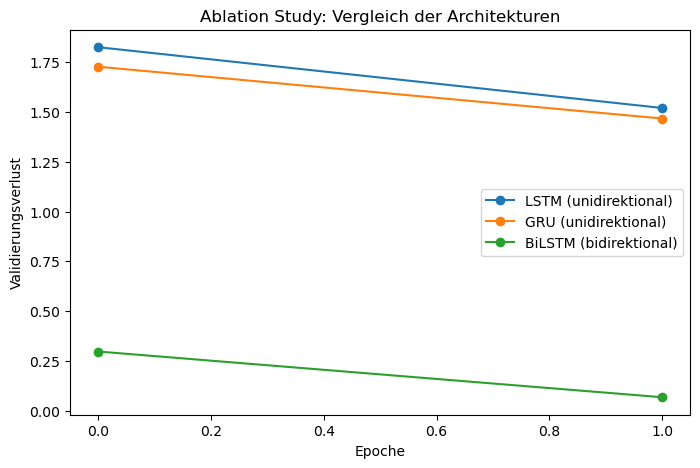


Zusammenfassung (finaler Validierungsverlust je Architektur):
  LSTM (unidirektional)     | val_loss=1.5197 | Perplexity=4.57
  GRU (unidirektional)      | val_loss=1.4667 | Perplexity=4.33
  BiLSTM (bidirektional)    | val_loss=0.0680 | Perplexity=1.07


In [20]:
import math

class RNNVariant(nn.Module):
    """Flexibles Modell für die Ablation Study: unterstützt RNN/LSTM/GRU, optional bidirektional."""
    def __init__(self, vocab_size, embedding_dim=64, hidden_dim=128,
                 num_layers=1, rnn_type="lstm", bidirectional=False, dropout=0.3):
        super().__init__()
        self.rnn_type = rnn_type.lower()
        self.bidirectional = bidirectional

        self.embedding = nn.Embedding(vocab_size, embedding_dim)

        rnn_cls = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[self.rnn_type]
        kwargs = dict(input_size=embedding_dim, hidden_size=hidden_dim,
                      num_layers=num_layers, batch_first=True,
                      bidirectional=bidirectional,
                      dropout=dropout if num_layers > 1 else 0.0)
        if self.rnn_type == "rnn":
            kwargs["nonlinearity"] = "tanh"
        self.rnn = rnn_cls(**kwargs)

        out_dim = hidden_dim * (2 if bidirectional else 1)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(out_dim, vocab_size)

    def forward(self, x, hidden=None):
        embedded = self.embedding(x)
        out, hidden = self.rnn(embedded, hidden)
        out = self.dropout(out)
        logits = self.fc(out)
        return logits, hidden


def run_ablation_variant(name, rnn_type, bidirectional, train_loader, val_loader,
                          device, num_epochs=2, hidden_dim=128, embedding_dim=64,
                          learning_rate=1e-3):
    """Trainiert eine RNN-Variante kurz und gibt die Verlust-Historie zurück."""
    print(f"\n=== Ablation: {name} ===")
    model_variant = RNNVariant(vocab_size=VOCAB_SIZE, embedding_dim=embedding_dim,
                                hidden_dim=hidden_dim, num_layers=1,
                                rnn_type=rnn_type, bidirectional=bidirectional).to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model_variant.parameters(), lr=learning_rate)

    history = {"train_loss": [], "val_loss": []}
    for epoch in range(1, num_epochs + 1):
        model_variant.train()
        total_loss = 0.0
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()
            logits, _ = model_variant(inputs)
            loss = criterion(logits.view(-1, logits.size(-1)), targets.view(-1))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model_variant.parameters(), 5.0)
            optimizer.step()
            total_loss += loss.item()
        train_loss = total_loss / len(train_loader)

        model_variant.eval()
        val_loss_total = 0.0
        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                logits, _ = model_variant(inputs)
                loss = criterion(logits.view(-1, logits.size(-1)), targets.view(-1))
                val_loss_total += loss.item()
        val_loss = val_loss_total / len(val_loader)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        print(f"  Epoche {epoch}/{num_epochs} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f}")

    return model_variant, history



ablation_train_subset = torch.utils.data.Subset(train_dataset, range(0, min(20000, len(train_dataset))))
ablation_val_subset = torch.utils.data.Subset(val_dataset, range(0, min(2000, len(val_dataset))))
ablation_train_loader = DataLoader(ablation_train_subset, batch_size=128, shuffle=True)
ablation_val_loader = DataLoader(ablation_val_subset, batch_size=128, shuffle=False)

variants = [
    ("LSTM (unidirektional)", "lstm", False),
    ("GRU (unidirektional)", "gru", False),
    ("BiLSTM (bidirektional)", "lstm", True),
]

ablation_results = {}
for name, rnn_type, bidir in variants:
    _, hist = run_ablation_variant(name, rnn_type, bidir,
                                    ablation_train_loader, ablation_val_loader,
                                    DEVICE, num_epochs=2)
    ablation_results[name] = hist

plt.figure(figsize=(8, 5))
for name, hist in ablation_results.items():
    plt.plot(hist["val_loss"], marker="o", label=name)
plt.xlabel("Epoche")
plt.ylabel("Validierungsverlust")
plt.title("Ablation Study: Vergleich der Architekturen")
plt.legend()
plt.show()

print("\nZusammenfassung (finaler Validierungsverlust je Architektur):")
for name, hist in ablation_results.items():
    final_val = hist["val_loss"][-1]
    perplexity = math.exp(final_val)
    print(f"  {name:25s} | val_loss={final_val:.4f} | Perplexity={perplexity:.2f}")

## 2- Validity Check — grammaire ABC

In [21]:
## Validity Check: "Grammatik"-Analyse der generierten ABC-Notation
import re

def check_abc_validity(abc_text):
    """
    Prüft grundlegende Grammatikregeln der ABC-Notation, jenseits von Top-1-Accuracy:
      - Balance der Wiederholungsklammern ('|:' / ':|')
      - Sinnvolles Ende (Schlusslinie)
      - Nur gültige ABC-Zeichen
      - Keine fehlerhaften Taktstrich-Sequenzen
    """
    result = {}

    valid_chars_pattern = re.compile(r"^[A-Ga-gzZ\^_=,'0-9/\|:\[\]\s\-\.><\(\)]*$")
    result["only_valid_characters"] = bool(valid_chars_pattern.match(abc_text))
    result["invalid_characters_found"] = sorted(set(
        ch for ch in abc_text if not valid_chars_pattern.match(ch)
    )) if not result["only_valid_characters"] else []

    open_repeats = abc_text.count("|:")
    close_repeats = abc_text.count(":|")
    result["repeat_brackets_balanced"] = (open_repeats == close_repeats)
    result["open_repeats"] = open_repeats
    result["close_repeats"] = close_repeats

    result["no_malformed_barlines"] = re.search(r"\|{3,}", abc_text) is None

    stripped = abc_text.strip()
    result["ends_logically"] = bool(re.search(r"(\|\]|\|\||:\|)\s*$", stripped))

    bar_count = len(re.findall(r"\|", abc_text))
    result["bar_count"] = bar_count
    result["has_at_least_one_bar"] = bar_count > 0

    binary_checks = [
        result["only_valid_characters"],
        result["repeat_brackets_balanced"],
        result["no_malformed_barlines"],
        result["ends_logically"],
        result["has_at_least_one_bar"],
    ]
    result["validity_score"] = sum(binary_checks) / len(binary_checks)

    return result


print("=== Validity Check: Generierte Stücke ===")
generated_samples = []
for i in range(3):
    seed = val_tunes[i][:150] if i < len(val_tunes) else train_tunes[i][:150]
    gen = generate_tune(model=model, seed_text=seed, char2idx=char2idx, idx2char=idx2char,
                         max_new_tokens=300, temperature=0.9, top_k=20, device=DEVICE)
    generated_samples.append(gen)
    report = check_abc_validity(gen)
    print(f"\nGeneriertes Stück {i+1} (Score: {report['validity_score']:.2f}):")
    for key, val in report.items():
        print(f"  {key}: {val}")

print("\n=== Referenz: Validity Check auf echten Trainingsstücken ===")
reference_scores = [check_abc_validity(t)["validity_score"] for t in train_tunes[:50]]
print(f"Durchschnittlicher Score über 50 echte Stücke: {sum(reference_scores)/len(reference_scores):.2f}")

avg_generated_score = sum(check_abc_validity(g)["validity_score"] for g in generated_samples) / len(generated_samples)
print(f"Durchschnittlicher Score über generierte Stücke: {avg_generated_score:.2f}")

=== Validity Check: Generierte Stücke ===

Generiertes Stück 1 (Score: 0.40):
  only_valid_characters: False
  invalid_characters_found: ['!', '"', 'K', 'L', 'M', 'X', 'm', 'r', 't']
  repeat_brackets_balanced: False
  open_repeats: 1
  close_repeats: 2
  no_malformed_barlines: True
  ends_logically: False
  bar_count: 39
  has_at_least_one_bar: True
  validity_score: 0.4

Generiertes Stück 2 (Score: 0.40):
  only_valid_characters: False
  invalid_characters_found: ['K', 'L', 'M', 'X']
  repeat_brackets_balanced: False
  open_repeats: 0
  close_repeats: 2
  no_malformed_barlines: True
  ends_logically: False
  bar_count: 34
  has_at_least_one_bar: True
  validity_score: 0.4

Generiertes Stück 3 (Score: 0.60):
  only_valid_characters: False
  invalid_characters_found: ['K', 'L', 'M', 'X']
  repeat_brackets_balanced: True
  open_repeats: 2
  close_repeats: 2
  no_malformed_barlines: True
  ends_logically: False
  bar_count: 32
  has_at_least_one_bar: True
  validity_score: 0.6

=== Refer

## 3. Programming Creativity 

In [22]:
## Programming Creativity: ABC -> Audio-Synthese (Sinuswellen) + Wiedergabe im Notebook
import math, struct, wave, re
from IPython.display import Audio, display

NOTE_SEMITONES = {"C": 0, "D": 2, "E": 4, "F": 5, "G": 7, "A": 9, "B": 11}

def abc_note_to_midi(letter, accidental, octave_marks):
    base = NOTE_SEMITONES[letter.upper()]
    midi = 60 + base + (12 if letter.islower() else 0)
    if accidental == "^":
        midi += 1
    elif accidental == "_":
        midi -= 1
    for mark in octave_marks:
        midi += 12 if mark == "'" else -12
    return midi


def parse_abc_notes(abc_text, default_note_length=1/8):
    body_lines = [line for line in abc_text.splitlines()
                  if not re.match(r"^[A-Za-z]:", line.strip())]
    body = " ".join(body_lines)

    token_pattern = re.compile(r"(\^|_|=)?([A-Ga-gzZ])([,']*)(\d*)(/?\d*)")
    notes = []
    for accidental, letter, octave_marks, num, denom in token_pattern.findall(body):
        if not letter:
            continue
        duration = default_note_length
        if num:
            duration *= int(num)
        if denom == "/":
            duration /= 2
        elif denom.startswith("/") and denom[1:].isdigit():
            duration /= int(denom[1:])

        if letter.upper() == "Z":
            notes.append((None, duration))
        else:
            midi = abc_note_to_midi(letter, accidental, octave_marks)
            notes.append((midi, duration))
    return notes


def synthesize_wav(notes, output_path="generated_tune.wav", tempo_bpm=120,
                    sample_rate=22050, amplitude=0.3):
    seconds_per_beat = 60.0 / tempo_bpm
    frames = []
    for midi, rel_duration in notes:
        duration_s = rel_duration * seconds_per_beat * 4
        n_samples = max(1, int(sample_rate * duration_s))
        if midi is None:
            frames.extend([0.0] * n_samples)
            continue
        freq = 440.0 * (2.0 ** ((midi - 69) / 12.0))
        for i in range(n_samples):
            t = i / sample_rate
            fade = min(1.0, i / 200.0, (n_samples - i) / 200.0)
            frames.append(amplitude * fade * math.sin(2 * math.pi * freq * t))

    with wave.open(output_path, "w") as wav_file:
        wav_file.setnchannels(1)
        wav_file.setsampwidth(2)
        wav_file.setframerate(sample_rate)
        packed = b"".join(struct.pack("<h", int(max(-1.0, min(1.0, s)) * 32767)) for s in frames)
        wav_file.writeframes(packed)
    return output_path


notes = parse_abc_notes(generated_abc)
print(f"{len(notes)} Noten/Pausen aus der generierten ABC-Sequenz extrahiert.")

audio_path = synthesize_wav(notes, output_path="generated_tune.wav", tempo_bpm=120)
print(f"Audio gespeichert unter: {audio_path}")
display(Audio(audio_path))

330 Noten/Pausen aus der generierten ABC-Sequenz extrahiert.
Audio gespeichert unter: generated_tune.wav
